key: 5f82c2d9cfeb0fa321d7d982f8bd1045


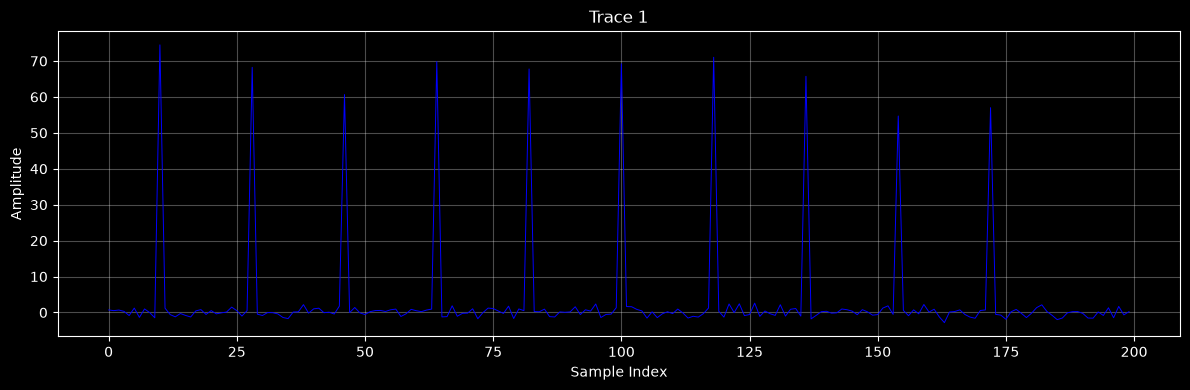

CPA byte 0: 100%|██████████| 5/5 [00:00<00:00, 29.47batch/s]


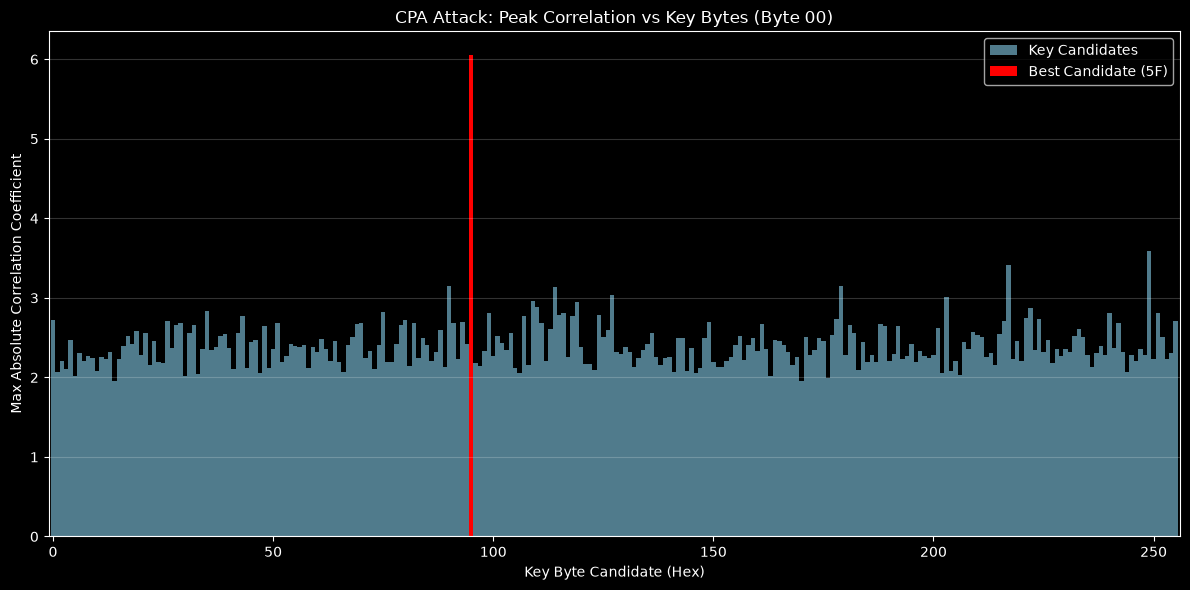

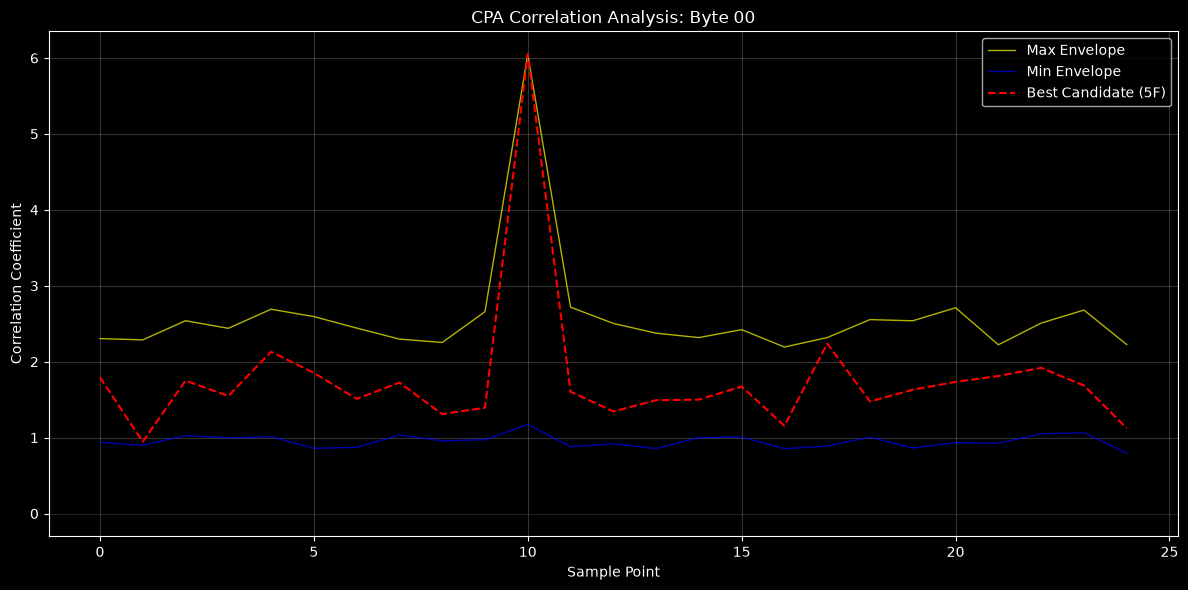

In [1]:
from scapyter.application.analysis.correlation.choosen_plaintext_analysis_service import ChosenPlaintextRegisterAttack
from scapyter.domain.value_object import RangeParameters, Range
from scapyter.infrastructure.h5_project_file_reader import H5ProjectFileReader
from scapyter.ui.correlation_plotter import CorrelationPlotter
from scapyter.ui.progressive_cpa_plotter import ProgressiveCpaPlotter
from scapyter.ui.trace_plotter import TracePlotter

trace_repo = H5ProjectFileReader("enc_byte0.h5")
print("key:", trace_repo.get_single_batch(0).key.tobytes().hex())

trace_plotter = TracePlotter(trace_repo)
trace_plotter.plot_single(index=1)

range_parameters = RangeParameters(
    trace_range=Range(0, 250),  # block where plaintext byte b varies
    sample_range=Range(0, 25),  # or narrow it, e.g. Range(35, 46)
)

cpta = ChosenPlaintextRegisterAttack(trace_repo)

result = cpta.attack_byte(byte_location=0, range_parameters=range_parameters)
plotter = CorrelationPlotter([result])
plotter.plot_correlation_vs_keys(0)
plotter.plot_correlation_vs_samples(0)

CPA byte 0: 100%|██████████| 5/5 [00:00<00:00, 28.57batch/s]


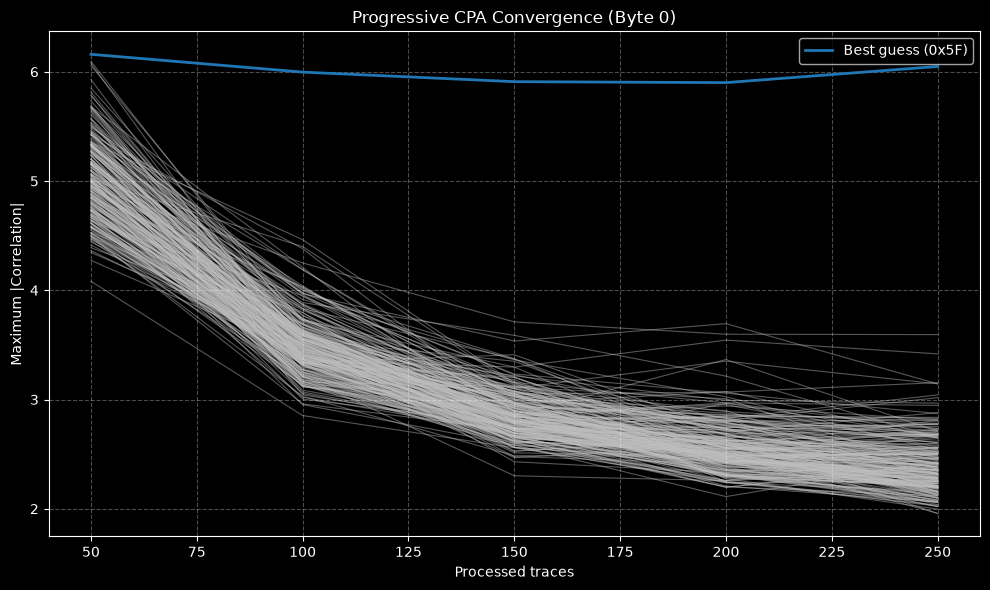

<Axes: title={'center': 'Progressive CPA Convergence (Byte 0)'}, xlabel='Processed traces', ylabel='Maximum |Correlation|'>

In [2]:
results = cpta.attack_byte_progressive(byte_location=0, step=50, batch_size=50, range_parameters=range_parameters)
plotter = ProgressiveCpaPlotter(results)
plotter.plot_convergence(byte_index=0)